In [ ]:
import pandas as pd
df = pd.read_csv('store_orders.csv')
df2 = pd.read_csv('store_customers.csv')

In [ ]:
df.head(10)

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10
5,5005,16,monitor,electronics,66.10,2026-06-10
6,5006,27,headset,electronics,86.67,2026-06-08
7,5007,36,dock,electronics,103.77,2026-05-21
8,5008,30,headset,electronics,267.39,2026-06-08
9,5009,14,chair,furniture,107.20,2026-05-24


In [ ]:
df2.head(10)

,customer_id,name,city,signup_year
0,1,Ana Lopez,Venice,2021
1,2,Ben Kim,Culver City,2023
2,3,Chloe Nguyen,Santa Monica,2021
3,4,Dev Patel,Los Angeles,2026
4,5,Elena Garcia,Culver City,2022
5,6,Farid Okafor,Culver City,2024
6,7,Grace Silva,Culver City,2025
7,8,Hugo Chen,Culver City,2023
8,9,Iris Ali,Inglewood,2026
9,10,Jon Brooks,Santa Monica,2021


In [ ]:
import sqlite3
con = sqlite3.connect('store.db')
df.to_sql('orders', con, index = False)
df2.to_sql('customers', con, index = False)
pd.read_sql('SELECT name FROM sqlite_master', con)

,name
0,orders
1,customers


In [ ]:
pd.read_sql('SELECT * FROM orders LIMIT 5', con)

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10


Looking for orders where the amount spent is over $100

In [ ]:
pd.read_sql('SELECT * FROM orders WHERE amount > 100 ORDER BY amount DESC', con)

,order_id,customer_id,product,category,amount,order_date
0,5153,20,dock,electronics,499.00,2026-05-25
1,5140,30,headset,electronics,295.36,2026-05-26
2,5047,901,headset,electronics,293.79,2026-05-15
3,5150,903,monitor,electronics,293.35,2026-06-06
4,5014,6,monitor,electronics,287.83,2026-05-22
...,...,...,...,...,...,...
79,5107,38,shelf,furniture,110.31,2026-05-17
80,5046,13,shelf,furniture,108.47,2026-05-28
81,5009,14,chair,furniture,107.20,2026-05-24
82,5007,36,dock,electronics,103.77,2026-05-21


Finding the amount spend within each category

In [ ]:
pd.read_sql('SELECT category, COUNT(*) AS num_orders, ROUND(AVG(amount), 2) AS avg_amount FROM orders GROUP BY category ORDER BY num_orders DESC ', con)

,category,num_orders,avg_amount
0,electronics,60,190.57
1,office,51,30.13
2,furniture,46,146.25
3,snacks,43,14.62


Finding the avergage amount spend by city

In [ ]:
pd.read_sql('SELECT c.city, SUM(o.amount) AS spend_per_customer_city FROM orders o JOIN customers c ON o.customer_id = c.customer_id GROUP BY c.city ORDER BY spend_per_customer_city DESC', con)

,city,spend_per_customer_city
0,Los Angeles,5862.99
1,Culver City,5316.88
2,Santa Monica,4017.93
3,Inglewood,2718.25
4,Torrance,1037.25
5,Venice,462.36


Comparing the rows in the orders table to the joined tables

In [ ]:
pd.read_sql('SELECT * FROM orders', con)

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10
...,...,...,...,...,...,...
195,5195,14,chair,furniture,201.59,2026-05-10
196,5196,5,pens,office,39.48,2026-05-09
197,5197,23,monitor,electronics,110.87,2026-06-10
198,5198,12,monitor,electronics,80.15,2026-06-13


In [ ]:
pd.read_sql('SELECT * FROM orders o JOIN customers c ON o.customer_id = c.customer_id', con)

,order_id,customer_id,product,category,amount,order_date,customer_id,name,city,signup_year
0,5000,4,paper,office,14.09,2026-05-25,4,Dev Patel,Los Angeles,2026
1,5001,15,planner,office,51.86,2026-05-08,15,Omar Garcia,Santa Monica,2022
2,5002,34,shelf,furniture,116.25,2026-06-03,34,Nina Patel,Venice,2024
3,5003,2,granola,snacks,19.72,2026-05-19,2,Ben Kim,Culver City,2023
4,5004,17,monitor,electronics,284.80,2026-05-10,17,Quinn Silva,Santa Monica,2022
...,...,...,...,...,...,...,...,...,...,...
190,5195,14,chair,furniture,201.59,2026-05-10,14,Nina Patel,Inglewood,2022
191,5196,5,pens,office,39.48,2026-05-09,5,Elena Garcia,Culver City,2022
192,5197,23,monitor,electronics,110.87,2026-06-10,23,Chloe Nguyen,Culver City,2024
193,5198,12,monitor,electronics,80.15,2026-06-13,12,Lena Kim,Santa Monica,2022


The original orders table has 200 rows while the joined tables only have 195. With what I know about joining tables, joins can only happen when rows have something to match to. With the 5 rows missing, I can only conclude that there wasn't a customer id within these rows to make a match.

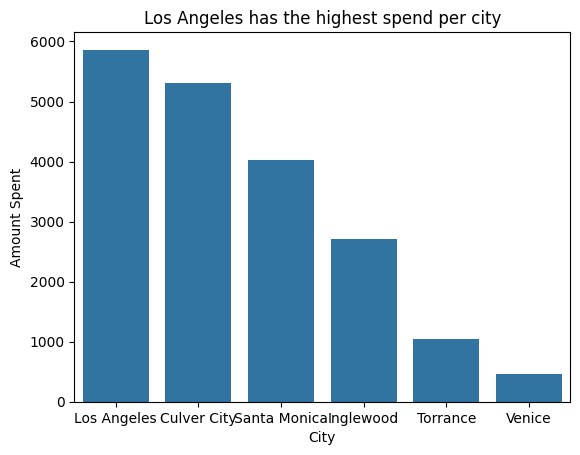

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
df_joined_table = pd.read_sql('SELECT c.city, SUM(o.amount) AS spend_per_customer_city FROM orders o JOIN customers c ON o.customer_id = c.customer_id GROUP BY c.city ORDER BY spend_per_customer_city DESC', con)
sns.barplot(data = df_joined_table, x = 'city', y = 'spend_per_customer_city')
plt.title('Los Angeles has the highest spend per city')
plt.xlabel('City')
plt.ylabel('Amount Spent')
plt.show()

Business Question: Which categories sell the most in each city?

In [ ]:
pd.read_sql('SELECT c.city, o.category, SUM(amount) AS amount_spent FROM orders o JOIN customers c ON o.customer_id = c.customer_id GROUP BY c.city ORDER BY amount_spent DESC', con)

,city,category,amount_spent
0,Los Angeles,office,5862.99
1,Culver City,snacks,5316.88
2,Santa Monica,office,4017.93
3,Inglewood,furniture,2718.25
4,Torrance,furniture,1037.25
5,Venice,furniture,462.36


Office supplies are the most popular category in Los Angeles and Santa Monica, Furniture is the most popular in Inglewood, Torrance, and Venice, and, finally, snacks are the most popular purchase in Culver City.

Since there is some confidential information in the database, I would strip the names entirely and only leave the order ids and customer ids as identifiers. That way, when the results are shared publicly we would not directly leak the identities of customers.

Appendix C.2 Assignment

In [75]:
con.execute('CREATE TABLE IF NOT EXISTS customers_new (ID INTEGER, name TEXT, city TEXT, zip_code INTEGER)')
con.execute("INSERT INTO customers_new VALUES(5002, 'Jane Doe', 'Inglewood', 90047)")
con.commit()

In [76]:
pd.read_sql('SELECT * FROM customers_new', con)

,ID,name,city,zip_code
0,5002,Jane Doe,Inglewood,90047


Appendix C.3 Assignment

In [78]:
pd.read_sql('SELECT name, city FROM customers WHERE city = "Los Angeles"', con)

,name,city
0,Dev Patel,Los Angeles
1,Kai Lopez,Los Angeles
2,Marco Nguyen,Los Angeles
3,Tara Brooks,Los Angeles
4,Ana Lopez,Los Angeles
5,Hugo Chen,Los Angeles
6,Jon Brooks,Los Angeles
7,Lena Kim,Los Angeles
8,Rosa Chen,Los Angeles


In [85]:
pd.read_sql('SELECT c.name, o.order_date, SUM(o.amount) AS amount_spent FROM orders o JOIN customers c ON o.customer_id = c.customer_id WHERE o.order_date LIKE "2026-05-%%" GROUP BY o.order_date ORDER BY amount_spent DESC', con)

,name,order_date,amount_spent
0,Chloe Nguyen,2026-05-15,1046.83
1,Farid Okafor,2026-05-05,821.37
2,Farid Okafor,2026-05-22,801.01
3,Quinn Silva,2026-05-10,755.71
4,Kai Lopez,2026-05-23,682.87
5,Nina Patel,2026-05-26,651.18
6,Rosa Chen,2026-05-17,616.13
7,Dev Patel,2026-05-25,593.07
8,Grace Silva,2026-05-02,584.63
9,Kai Lopez,2026-05-20,561.29


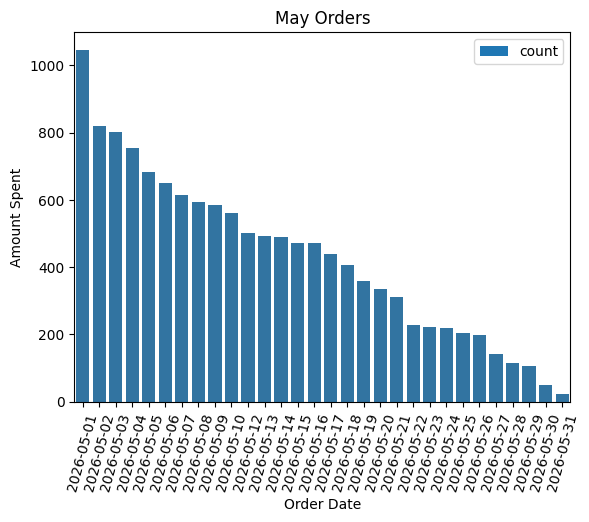

In [107]:
df_may_orders = pd.read_sql('SELECT c.name, o.order_date, SUM(o.amount) AS amount_spent FROM orders o JOIN customers c ON o.customer_id = c.customer_id WHERE o.order_date LIKE "2026-05-%%" GROUP BY o.order_date ORDER BY amount_spent DESC', con)
df_may_orders['order_date'].value_counts().sort_index().plot.bar()
sns.barplot(data = df_may_orders, x = 'order_date', y = 'amount_spent')
plt.title('May Orders')
plt.xlabel('Order Date')
plt.xticks(rotation = 75)
plt.ylabel('Amount Spent')
plt.show()